## Introducción

Este cuaderno implementa el **modelo de dos regiones en coordenada desplazada** $z' = z - d$, resolviendo la ecuación de difusión en el cilindro $\rho \in [0, R]$, $z' \in [0, L]$ con difusividades por zonas:

$$D(z') = \begin{cases} D_1 = 2\times10^1\,\text{nm}^2/\mu\text{s} & z' \leq z_c \\ D_2 = 2\times10^3\,\text{nm}^2/\mu\text{s} & z' > z_c \end{cases}$$

Los modos radiales $J_0(\alpha_n \rho)$ se obtienen de la ecuación trascendental de Robin ($\kappa = 0$). Los modos axiales $Z_{nm}(z')$ se construyen analíticamente en cada región (combinación de seno y coseno piezados en $z_c$) e imponen continuidad de $P$ y $D\partial_{z'} P$ en la interfaz.

Parámetros: $d = 15\,\text{nm}$, $R = L = 50d$, $z_c = 0.75 R/d$, $D_\text{eff} \approx 336\,\text{nm}^2/\mu\text{s}$ (media armónica), 100 modos radiales y 100 axiales. Se incluye análisis de truncamiento y heatmap de error relativo.

In [1]:
import numpy as np
from scipy.special import jn_zeros
from scipy.optimize import root_scalar, brentq
from scipy.linalg import eigh_tridiagonal
import matplotlib.pyplot as plt
import scipy.special as sp
from scipy.special import jv, jn_zeros
from scipy.integrate import quad
from joblib import Parallel, delayed
from matplotlib.colors import LogNorm
from scipy.special import logsumexp

# Solución de la ecuación de difusión del modelo de dos regiones (_Two-Region Model_)

In [2]:
# Parámetros físicos
d = 15                # nm Profundidad de NV
D1 = 2e1              # nm²/us (región superficial)
D2 = 2e3              # nm²/us (región volumétrica)
L = R = 50*d         # nm (altura total), nm (radio del cilindro)
z_c = 2.5*d           # 37.5 nm (altura de la interfaz, desde la superficie)
# (antes: 0.75*R/d, que es adimensional; 2.5*d da el mismo valor)
kappa = 0.0           # nm/µs coeficiente de absorción superficial (Robin en la superficie)
n_modes_radial = 100   # Número de modos radiales
m_max = 100            # Número de modos axiales por modo radial
N_z = N_r = 15000     # Número de nodos en z y rho

In [3]:
##############################################################################
# 1. Solución Radial R(ρ)
##############################################################################

def D_eff_tworegion(D1, D2, z_c, L):
    L1, L2 = z_c, L - z_c
    return (L1 + L2) / (L1/D1 + L2/D2)

D_eff=D_eff_tworegion(D1, D2, z_c, L)
D_eff

336.1344537815126

In [4]:
T_D=d**2/D_eff
T_D # [us]

0.669375

In [5]:
# Solución de la ecuación trascendental
def robin_eq(alpha):
    return alpha * sp.jv(1, alpha * R) - (kappa / D_eff) * jv(0, alpha * R)

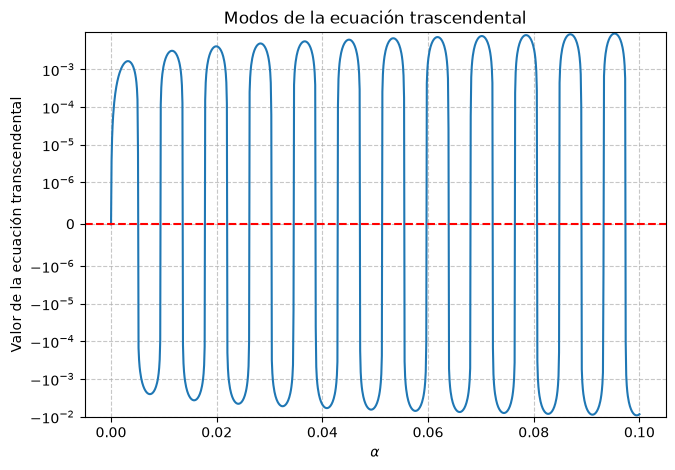

In [6]:
plt.figure(figsize=(7.5,5))
alpha_plot=np.linspace(0.0,0.1,1000)
plt.plot(alpha_plot,robin_eq(alpha_plot))
# plt.legend()
plt.title("Modos de la ecuación trascendental")
plt.ylabel("Valor de la ecuación transcendental")
plt.xlabel(r"$\alpha$")
plt.axhline(0, color='red', linestyle='--')
plt.yscale('symlog', linthresh=1e-6)
plt.grid(ls='--', alpha=0.7)
plt.savefig("figuras/transcendental_radial_tworegion_z'.pdf", bbox_inches='tight')
plt.show()

In [7]:
# Estimar raíces con brentq en intervalos [a, b] con cambio de signo
alpha_min = 0.0
alpha_n = []
step = 0.0001  # Paso inicial para buscar raíces

alpha_current = alpha_min
while len(alpha_n) < n_modes_radial:
    # Buscar raíces en el intervalo [Lambda_current, Lambda_current + step]
    try:
        root = brentq(robin_eq, alpha_current, alpha_current + step, xtol=1e-6)
        alpha_n.append(root)
        alpha_current = root + step  # Mover el inicio para la próxima búsqueda
    except ValueError:
        alpha_current += step
alpha_n=np.array(alpha_n)

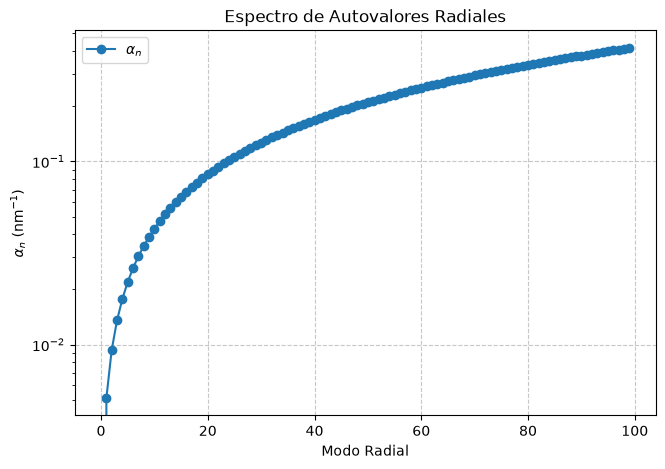

In [8]:
plt.figure(figsize=(7.5, 5))
plt.semilogy(alpha_n, 'o-', label=r"$\alpha_n$")
plt.xlabel('Modo Radial')
plt.ylabel(r'$\alpha_n$ (nm$^{-1}$)')
plt.title('Espectro de Autovalores Radiales')
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig("figuras/alpha_n_z'.pdf", bbox_inches='tight')
plt.show()
plt.close()

In [9]:
def R_func(alpha, rho):
    """
    Calcula R_n(rho) = J0(alpha_n * rho) normalizados con la norma analítica
      ∫₀ᴿ J₀²(αₙ ρ) ρ dρ = (R²/2)[J₀²(αₙR) + J₁²(αₙR)].

    Args:
        alpha_n: array de raíces αₙ, shape (n_modes,)
        rho_vals: escalar o array de posiciones radiales, shape (m,)

    Returns:
        R_normed: array (n_modes, m) de los modos normalizados
        norms:    array (n_modes,) con el valor exacto de la norma
    """
   # 1) Aseguramos que alpha_n y rho_vals sean arrays 1D
    alpha_arr = np.atleast_1d(alpha)              # shape (n_modes,)
    rho_arr   = np.atleast_1d(rho)             # shape (m,)

    # 2) Creamos vistas 2D para broadcasting
    alpha = alpha_arr.reshape(-1, 1)                # (n_modes, 1)
    rho   = rho_arr.reshape(1, -1)                  # (1, m)

    # 3) Evaluamos el modo sin normalizar
    R_matrix = sp.jv(0, alpha * rho)                   # (n_modes, m)

    # 4) Calculamos la norma analítica usando alpha_arr (no el escalar viejo)
    J0R = sp.jv(0, alpha_arr * R)                      # (n_modes,)
    J1R = sp.jv(1, alpha_arr * R)                    # (n_modes,)
    norms = 0.5 * R**2 * (J0R**2 + J1R**2)           # (n_modes,)

    # 5) Aseguramos que norms sea un array 1D
    norms = np.atleast_1d(norms)

    # 6) Factor de normalización
    N = 1.0 / np.sqrt(norms)                        # (n_modes,)

    # 7) Aplicamos normalización por filas
    R_normed = N[:, None] * R_matrix                # (n_modes, m)

    return R_normed, np.sqrt(norms)

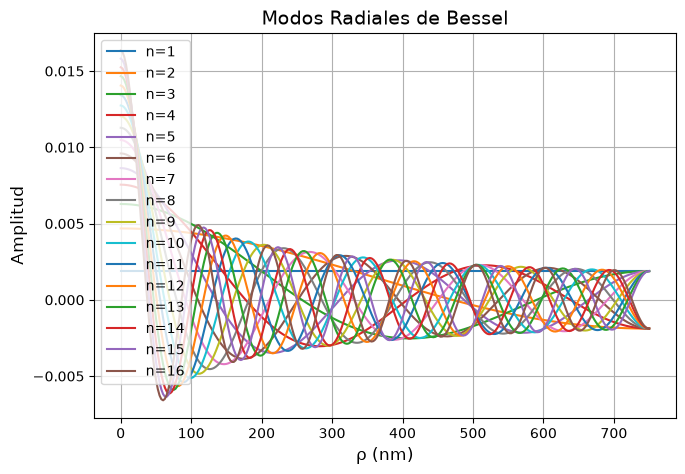

In [10]:
rho_nodes_plot = np.linspace(0.0, R, 300)
R_values, R_norms = R_func(alpha_n, rho_nodes_plot)

# Graficar modos radiales
plt.figure(figsize=(7.5, 5))
for n in range(min(16, n_modes_radial)):
    plt.plot(rho_nodes_plot, R_values[n], label=f"n={n+1}", linewidth=1.5)

plt.xlabel("ρ (nm)", fontsize=12)
plt.ylabel("Amplitud", fontsize=12)
plt.title("Modos Radiales de Bessel", fontsize=14)
plt.legend()
plt.grid(True)
plt.savefig("figuras/modos_radiales_z'.pdf", bbox_inches="tight")
plt.show()
plt.close()

In [11]:
##############################################################################
# 2. Ecuación trascendental (dos ramas)
##############################################################################
# En cada región, -D Z'' + alpha^2 D Z = Lambda^2 Z se reduce a
#
#     Z'' = -(Lambda^2 - alpha^2 D_i)/D_i * Z = -k_i^2 Z
#
# de modo que la solución es TRIGONOMÉTRICA si k_i^2 > 0 y HIPERBÓLICA si
# k_i^2 < 0. El espectro está acotado por abajo por alpha^2 * min(D) = alpha^2 D1,
# así que en la banda   alpha^2 D1 <= Lambda^2 < alpha^2 D2   la región 2 es
# evanescente: son los modos localizados en la capa superficial lenta, que son
# los más lentos y los que dominan la cola de G(t).
#
# La versión anterior aplicaba np.abs() a ambas betas, lo que sustituye las
# funciones hiperbólicas por trigonométricas (rama equivocada), y además sólo
# buscaba raíces a partir de Lambda = alpha*sqrt(D2), de modo que esa banda
# entera quedaba fuera.

Z_OFF = 0.0          # origen de la coordenada axial del cuaderno
Z_INT = Z_OFF + z_c    # posición de la interfaz


def _tr_fv(alpha, k, kap, D1_, D2_, z_c_, N=20001):
    """Autovalores Lambda^2 por volumen finito, con D constante a trozos.

    Sirve solo para LOCALIZAR el espectro: devuelve todos los autovalores en
    orden y sin saltarse ninguno. Cada valor se pule despues con brentq sobre
    la ecuacion trascendental, de modo que la raiz final es la analitica.
    """
    zg = np.unique(np.concatenate([np.linspace(0.0, L, N), [z_c_]]))
    N = len(zg)
    h = np.diff(zg)
    Dv = np.where(zg < z_c_ - 1e-12, D1_,
                  np.where(zg > z_c_ + 1e-12, D2_, 2*D1_*D2_/(D1_ + D2_)))
    w = np.empty(N); w[1:-1] = 0.5*(h[:-1] + h[1:]); w[0] = h[0]/2; w[-1] = h[-1]/2
    Dh = 2*Dv[:-1]*Dv[1:]/(Dv[:-1] + Dv[1:])
    off = -Dh/h
    dia = np.zeros(N)
    dia[1:-1] = Dh[:-1]/h[:-1] + Dh[1:]/h[1:]
    dia[0]  = Dh[0]/h[0] + kap          # Robin en la superficie
    dia[-1] = Dh[-1]/h[-1]              # Neumann arriba
    dia += alpha**2 * Dv * w
    s = 1.0/np.sqrt(w)
    return eigh_tridiagonal(dia*s*s, off*s[:-1]*s[1:],
                            select='i', select_range=(0, k-1), eigvals_only=True)


def _region1(zeta, Lam2, alpha, kap=kappa):
    """Solución en 0 <= zeta <= z_c que cumple D1 Z'(0) = kap Z(0).

    Devuelve (Z(zeta), Z(z_c), Z'(z_c)).
    """
    a1 = (Lam2 - alpha**2 * D1) / D1
    if a1 > 0:
        k = np.sqrt(a1)
        cc, sc = np.cos(k * z_c), np.sin(k * z_c)
        return (np.cos(k * zeta) + (kap / (D1 * k)) * np.sin(k * zeta),
                cc + (kap / (D1 * k)) * sc,
                -k * sc + (kap / D1) * cc)
    if a1 == 0:
        return (1.0 + (kap / D1) * zeta, 1.0 + (kap / D1) * z_c, kap / D1)
    q = np.sqrt(-a1)
    cc, sc = np.cosh(q * z_c), np.sinh(q * z_c)
    return (np.cosh(q * zeta) + (kap / (D1 * q)) * np.sinh(q * zeta),
            cc + (kap / (D1 * q)) * sc,
            q * sc + (kap / D1) * cc)


def _region2(zeta, Lam2, alpha):
    """Solución en z_c <= zeta <= L que cumple Z'(L) = 0 (Neumann).

    Devuelve (g(zeta), g(z_c), g'(z_c)), escalada a O(1).
    """
    a2 = (Lam2 - alpha**2 * D2) / D2
    u, uc = zeta - L, z_c - L
    if a2 > 0:
        k = np.sqrt(a2)
        return np.cos(k * u), np.cos(k * uc), -k * np.sin(k * uc)
    if a2 == 0:
        return np.ones_like(np.asarray(zeta, dtype=float)), 1.0, 0.0
    q = np.sqrt(-a2)
    ref = np.cosh(q * (L - z_c))       # evita desbordes en los modos evanescentes
    return np.cosh(q * u) / ref, np.cosh(q * uc) / ref, q * np.sinh(q * uc) / ref


def transcendental_eq(Lam2, alpha, kap=kappa):
    """Continuidad de Z y del flujo D Z' en la interfaz zeta = z_c.

    OJO: el argumento es Lambda^2 (el autovalor), no Lambda.
    """
    _, Zc, dZc = _region1(0.0, Lam2, alpha, kap)
    _, gc, dgc = _region2(0.0, Lam2, alpha)
    return D1 * dZc * gc - D2 * dgc * Zc

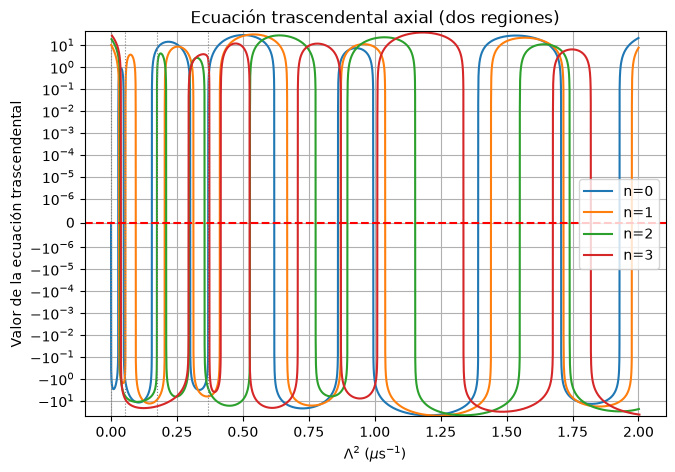

In [12]:
plt.figure(figsize=(7.5,5))
for n in range(4):
    lo = alpha_n[n]**2 * D1
    Lam2 = np.linspace(lo, lo + 2.0, 4000)
    vals = np.array([transcendental_eq(x, alpha_n[n]) for x in Lam2])
    plt.plot(Lam2, vals, label=f'n={n}')
    plt.axvline(alpha_n[n]**2 * D2, ls=':', lw=0.8, color='gray')
plt.legend()
plt.title("Ecuación trascendental axial (dos regiones)")
plt.ylabel("Valor de la ecuación trascendental")
plt.xlabel(r"$\Lambda^2$ ($\mu$s$^{-1}$)")
plt.axhline(0, color='red', linestyle='--')
plt.yscale('symlog', linthresh=1e-6)
plt.grid(True)
plt.savefig("figuras/transcendental_axial_tworegion_z'.pdf", bbox_inches="tight")
plt.show()
plt.close()
# Las líneas de puntos marcan alpha_n^2 D2: a su izquierda están los modos
# superficiales evanescentes que el barrido anterior no buscaba.

In [13]:
##############################################################################
# 3. Búsqueda de autovalores Lambda^2 para un alpha_n dado
##############################################################################

def find_m_roots(alpha, kap=kappa, k=None):
    """Raices Lambda^2 del problema axial de dos regiones.

    El espectro se localiza con una diagonalizacion en volumen finito, que
    devuelve todos los autovalores en orden, y cada valor se pule con brentq
    sobre la ecuacion trascendental. Un barrido por cambio de signo no sirve:
    se salta los pares casi degenerados de las dos familias de modos, en los
    que F cruza dos veces dentro del mismo paso.
    """
    if k is None:
        k = m_max
    aprox = _tr_fv(alpha, k, kap, D1, D2, z_c)
    lo = alpha**2 * D1
    out = np.empty(k)
    for _i, _lam in enumerate(aprox):
        _lam = max(_lam, lo)
        _dm = _lam - aprox[_i-1] if _i > 0 else (aprox[1] - aprox[0] if k > 1 else _lam)
        _dp = aprox[_i+1] - _lam if _i + 1 < k else _dm
        _w = 0.35*max(min(abs(_dm), abs(_dp)), 1e-9) + 1e-9
        _raiz = _lam
        for _fac in (1.0, 3.0, 9.0):
            _a, _b = max(_lam - _fac*_w, lo), _lam + _fac*_w
            _fa = transcendental_eq(_a, alpha, kap)
            _fb = transcendental_eq(_b, alpha, kap)
            if np.isfinite(_fa) and np.isfinite(_fb) and _fa*_fb < 0:
                _raiz = brentq(transcendental_eq, _a, _b, args=(alpha, kap,), xtol=1e-13, rtol=8.9e-16)
                break
        out[_i] = _raiz
    if alpha == 0.0 and kap == 0.0:
        out[0] = 0.0      # modo uniforme
    return out

eigenvalues_ax = Parallel(n_jobs=4, verbose=1)(
    delayed(find_m_roots)(alpha) for alpha in alpha_n)
eigenvalues_ax = np.array(eigenvalues_ax)

print("Lambda^2 mas bajo por modo radial (n=0..4):",
      np.array2string(eigenvalues_ax[:5, 0], precision=5))
print("modos por debajo de alpha_n^2 D2 (los que antes se perdian):",
      [int(np.sum(eigenvalues_ax[n] < alpha_n[n]**2 * D2)) for n in range(min(5, n_modes_radial))])


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    6.5s


Lambda^2 mas bajo por modo radial (n=0..4): [0.      0.03049 0.03471 0.03736 0.04034]
modos por debajo de alpha_n^2 D2 (los que antes se perdian): [0, 1, 2, 2, 3]


[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:   13.7s finished


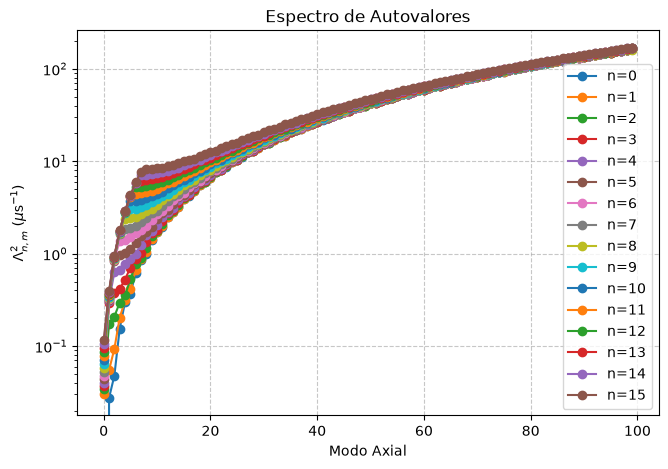

In [14]:
# Graficar espectro de autovalores
plt.figure(figsize=(7.5,5))
for n in range(min(16,n_modes_radial)):
    evals = eigenvalues_ax[n]
    plt.semilogy(evals, 'o-', label=f'n={n}')
plt.xlabel('Modo Axial')
plt.ylabel(r'$\Lambda_{n,m}^2$ ($\mu$s$^{-1}$)')
plt.title('Espectro de Autovalores')
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig("figuras/eigenvalues_tworegion_z'.pdf", bbox_inches='tight')
plt.show()
plt.close()

In [15]:
##############################################################################
# 4. Z(z) sin coeficientes
##############################################################################
z_nodes = np.linspace(Z_OFF, Z_OFF + L, N_z)


def fz_raw(z_val, n, m):
    """Autofunción axial sin normalizar, en la coordenada del cuaderno."""
    zeta = np.asarray(z_val, dtype=float) - Z_OFF
    Lam2 = eigenvalues_ax[n][m]
    alpha = alpha_n[n]

    Z1, Zc, dZc = _region1(zeta, Lam2, alpha, kappa)
    g, gc, dgc = _region2(zeta, Lam2, alpha)

    # amplitud de la región 2 por la ecuación de empalme mejor condicionada
    if abs(gc) >= abs(dgc) * (L - z_c):
        A = Zc / gc
    else:
        A = D1 * dZc / (D2 * dgc)

    return np.where(zeta <= z_c, Z1, A * g)


# Normalización  int Z^2 dz = 1  sobre el dominio físico [Z_OFF, Z_OFF + L]
C_nm = np.zeros((n_modes_radial, m_max))
for n in range(n_modes_radial):
    for m in range(m_max):
        Z_vals = fz_raw(z_nodes, n, m)
        C_nm[n, m] = 1.0 / np.sqrt(np.trapezoid(Z_vals**2, z_nodes))


def fz(z_val, n, m):
    return C_nm[n, m] * fz_raw(z_val, n, m)


# Comprobación de ortonormalidad sobre un bloque pequeño de modos
_k = min(6, m_max)
_Z = np.array([fz(z_nodes, 0, m) for m in range(_k)])
_G = np.trapezoid(_Z[:, None, :] * _Z[None, :, :], z_nodes, axis=2)
print(f"|Gram - I| para n=0, {_k} modos: {np.abs(_G - np.eye(_k)).max():.2e}")

|Gram - I| para n=0, 6 modos: 1.80e-07


In [16]:
# Para cada modo (n,m) verificar:
z_test = (z_c) * np.ones(100)
left = fz_raw(z_c - 1e-6, n, m)  # Límite izquierdo
right = fz_raw(z_c + 1e-6, n, m) # Límite derecho
assert np.allclose(left, right, atol=1e-4)

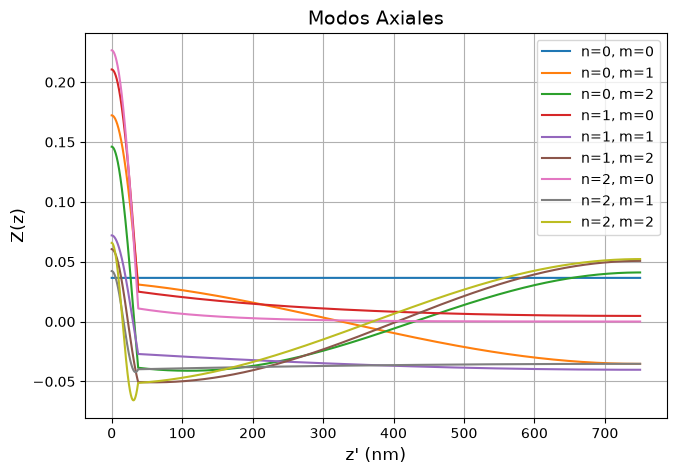

In [17]:
plt.figure(figsize=(7.5,5))
for n in range(3):
    for m in range(3):
        Zs=[]
        for z_val in z_nodes:
            Zs.append(fz(z_val,n,m))
        plt.plot(z_nodes,np.array(Zs), label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel("z' (nm)", fontsize=12)
plt.ylabel("Z(z)", fontsize=12)
plt.title("Modos Axiales", fontsize=14)
plt.legend()
plt.grid(True)
plt.savefig("figuras/modos_axiales_tworegion_z'.pdf", bbox_inches="tight")
plt.show()
plt.close() 

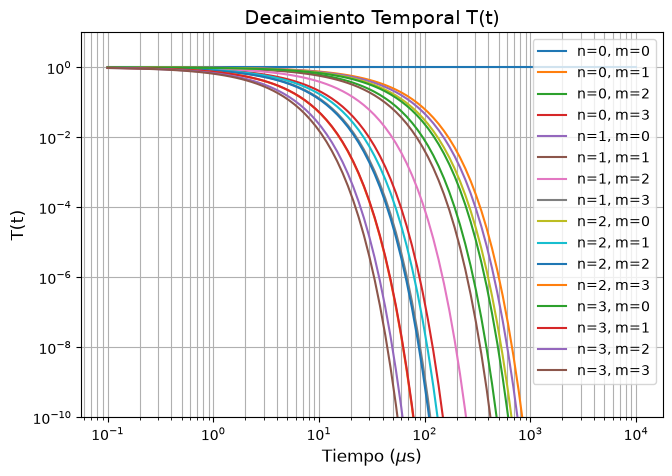

In [18]:
##############################################################################
# 5. Término Temporal T(t)
##############################################################################
# Ahora, para cada eigenvalor (de la parte axial) usaremos el valor absoluto
# para que T(t)=exp(-|λ| t) decaiga.
def T(t, lam):
    return np.exp(-lam * t)

# Graficamos T(t) para los modos del sistema axial
plt.figure(figsize=(7.5,5))
t_plot = np.logspace(-1, 4, 100)
for n in range(min(4,n_modes_radial)):
    for m in range(min(4, m_max)):
        lam = eigenvalues_ax[n,m]
        plt.loglog(t_plot, T(t_plot, lam), label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel(r"Tiempo ($\mu$s)", fontsize=12)
plt.ylabel("T(t)", fontsize=12)
plt.ylim(1e-10,1e1)
plt.title("Decaimiento Temporal T(t)", fontsize=14)
plt.legend()
plt.grid(True, which="both")
plt.savefig("figuras/T_t_tworegion_z'.pdf", bbox_inches="tight")
plt.show()
plt.close()

In [19]:
##############################################################################
# 6. Cálculo de Coeficientes A_{nm}
##############################################################################
# Se asume que la condición inicial es:
#     P(ρ, z, 0) ∝ δ(ρ-ρ0) δ(z-z0) / (2πρ0)
# Con ρ0 = 750 nm y z0 = 10 nm.
# --- Parámetros de la delta ---
rho0, z0 = 0.0,  0.0  # centro (nm)

# --- 1) Mallado de cuadratura cilíndrica (ρ, z) ---
N_quad = 1000
rho_quad = np.linspace(0.0, R, N_quad)   # nodos radiales
z_quad   = np.linspace(0.0, L, N_quad)   # nodos axiales

# (1) Evaluar modos radiales en rho0:
#     R_func(alpha_n, x) devuelve R_mat[n,i] = R_n(x)
#     Usamos un punto x = rho0
a0 = np.array([rho0])                       # array de un punto
R0, _ = R_func(alpha_n, a0)                # R0.shape = (n_modes_radial, 1)
R0 = R0[:, 0]                              # ahora vector (n_modes_radial,)

# (2) Evaluar modos axiales en z0
def eval_Z_at(z_val):
    Z0 = np.empty((n_modes_radial, m_max))
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z0[n, m] = fz(z0,n,m)
    return Z0

Z0 = eval_Z_at(z0)  # Z0.shape = (n_modes_radial, m_max)

# (4) Coeficientes modal A_nm: producto de R0 y Z0
#     A_nm_delta[n,m] = R_n(rho0) * Z_{n,m}(z0)
A_nm = R0[:, None] * Z0            # shape (n_modes_radial, m_max)
print(f"A_nm_delta shape: {A_nm.shape}")

A_nm_delta shape: (100, 100)


In [20]:
##############################################################################
## # 7. Densidad de Probabilidad P(ρ,z,t)
##############################################################################
# Malla de cuadratura para las integrales modales F_nm.
# El integrando esta muy concentrado cerca de la superficie: f decae como z^-3 y
# los modos axiales tienen capa limite ahi. Con malla uniforme y suma rectangular
# (dr*dz*sum) la suma modal (5/16pi) sum F_nm^2 llegaba a superar a la integral
# directa (5/16pi) int f^2 rho drho dz, imposible para Parseval truncada.
# Se agrupan nodos en la superficie con la misma transformacion sinh de la malla
# axial y se usan pesos del trapecio.
N_quad = 2000
_s = np.arange(N_quad) / (N_quad - 1)
rho_nodes = np.linspace(0.0, R, N_quad)
z_nodes   = L * np.sinh(3.0 * _s) / np.sinh(3.0)          # [0, L] = z', apretada en z'=0


def pesos_trapecio(x):
    """Pesos de la regla del trapecio para una malla posiblemente no uniforme."""
    h = np.diff(x)
    w = np.empty_like(x)
    w[1:-1] = 0.5 * (h[:-1] + h[1:])
    w[0]    = 0.5 * h[0]
    w[-1]   = 0.5 * h[-1]
    return w


w_rho = pesos_trapecio(rho_nodes)
w_z   = pesos_trapecio(z_nodes)

# Precompute Bessel J0 for all radial modes and rho
# J0_mat shape: (n_modes, Nr)
R0_mat,_ = R_func(alpha_n, rho_nodes)

# Precompute axial modes Z_tens: shape (Nz, n_modes, m_max)
Nz = len(z_nodes)
n_modes, m_max = eigenvalues_ax.shape
Z_tens = np.zeros((Nz, n_modes, m_max))
for n in range(n_modes):
    for m in range(m_max):
        Z_tens[:, n, m] = fz(z_nodes, n, m)

In [21]:
def compute_P_vec(t, eigenvalues_ax, Z_tens, R0_mat, A_nm):
    """
    Vectorized computation of P(rho, z, t).
    
    Parameters:
    - t:        scalar time

    Returns:
    - P: 2D array of shape (Nz, Nr)
    """
    
    # Temporal decay T: shape (n_modes, m_max)
    T_decay = np.exp(-eigenvalues_ax * t)
    # Combine coefficients with normalization and decay: shape (n_modes, m_max)
    W = A_nm * T_decay
    
    # Sum over axial modes m → B shape (Nz, n_modes)
    B = np.sum(Z_tens * W[None, :, :], axis=2)
    
    # Combine with radial modes → S shape (Nr, Nz)
    # J0_mat.T: (Nr, n_modes), B.T: (n_modes, Nz)
    S = np.dot(R0_mat.T, B.T)
    
    # Return absolute value, shaped back to (Nz, Nr)
    return np.maximum(S.T,0)

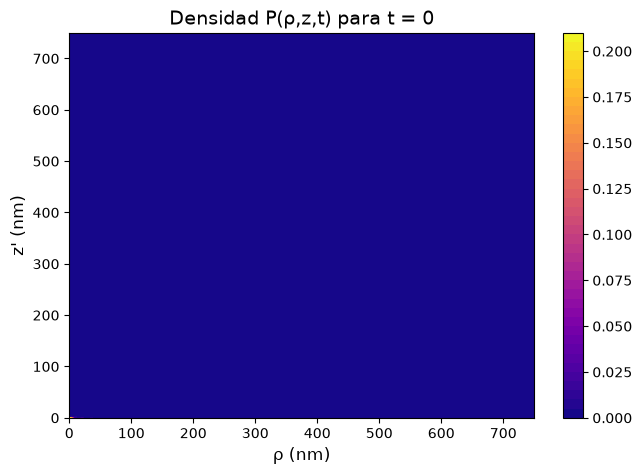

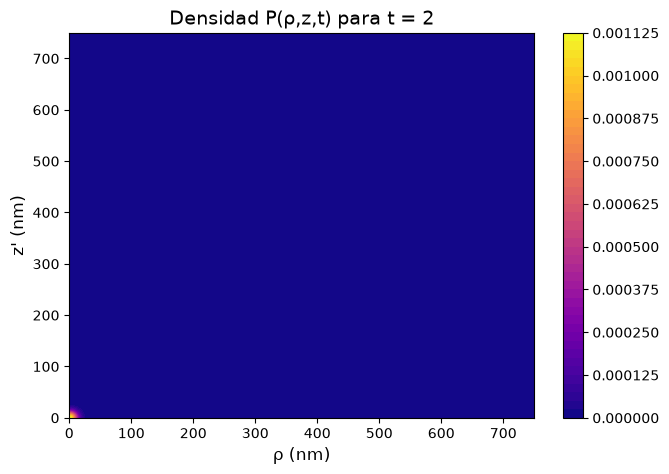

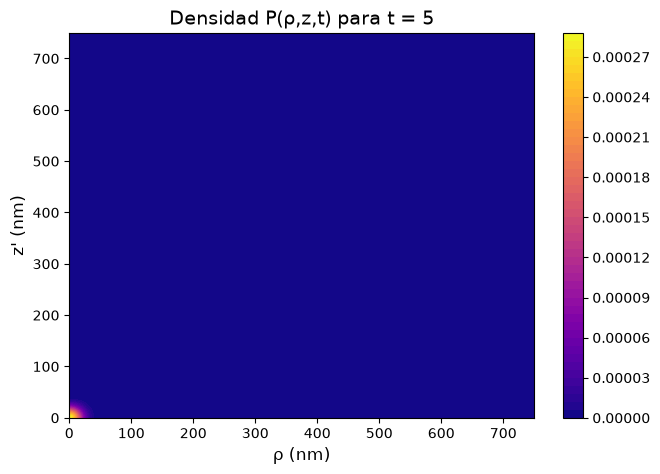

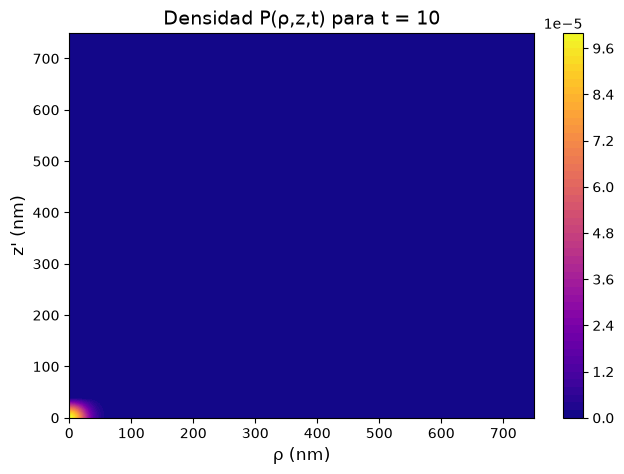

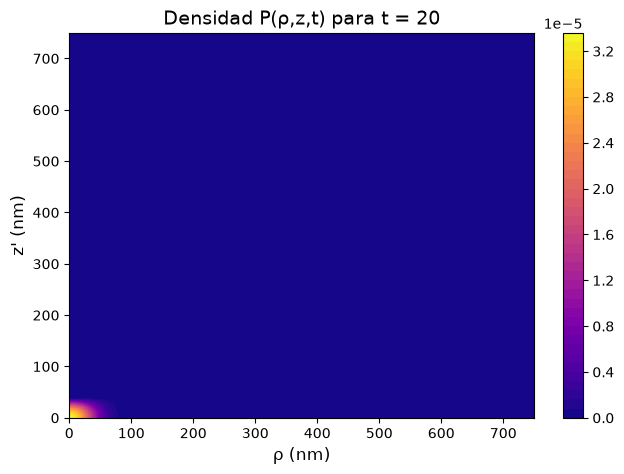

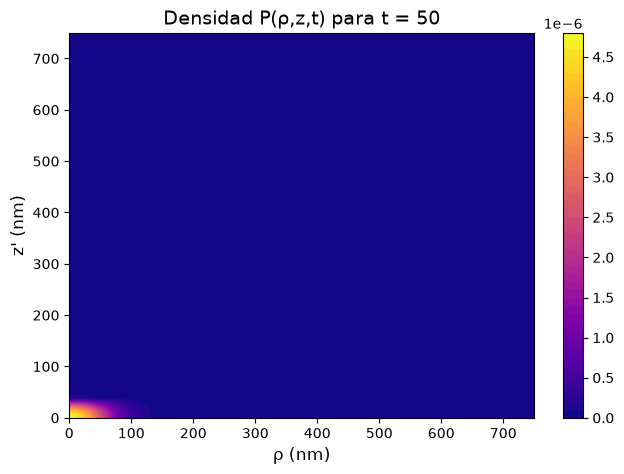

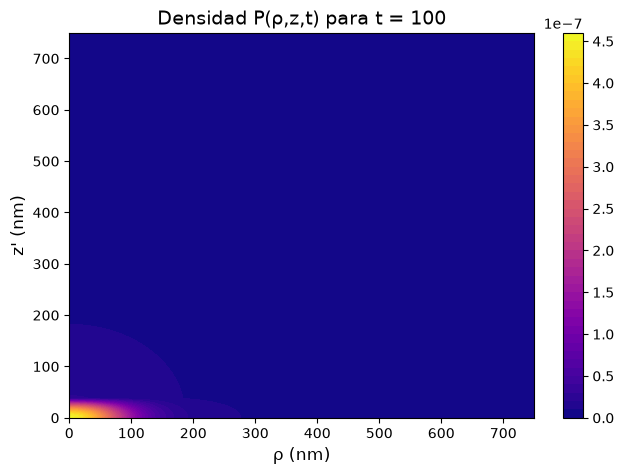

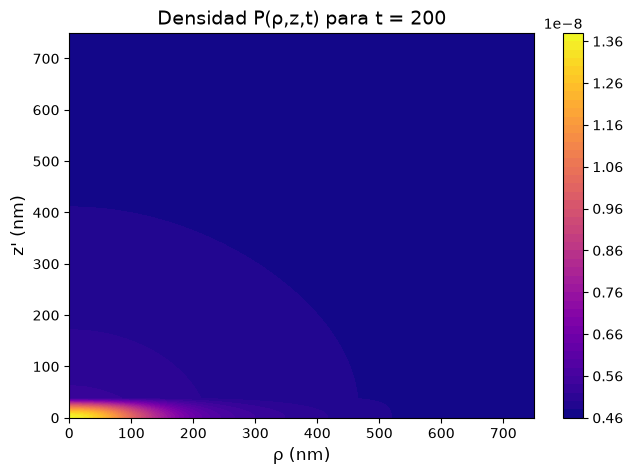

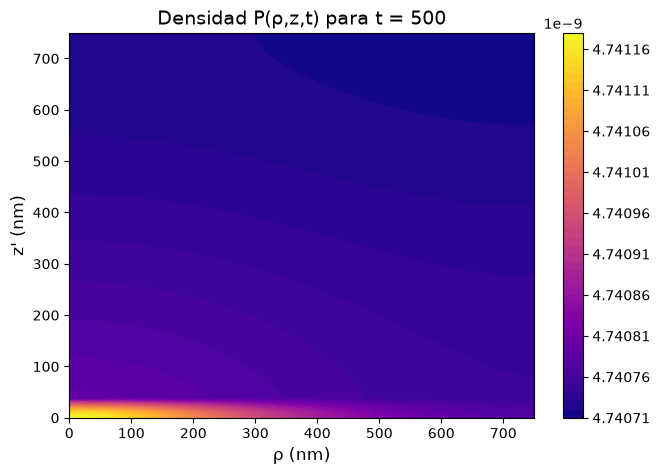

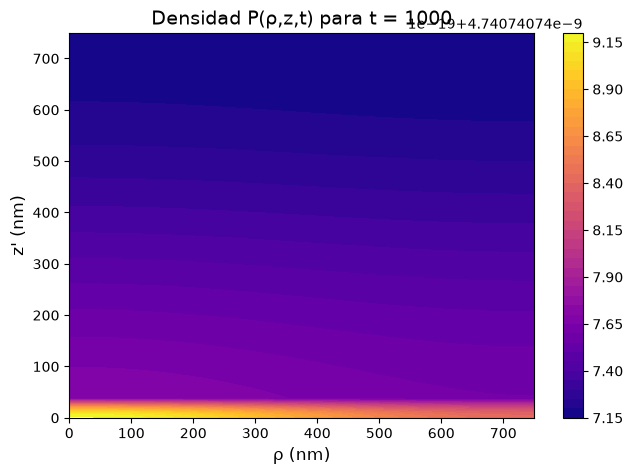

In [22]:
for t_val in [0,2,5,10,20,50,100,200,500,1000]:
    P_val = compute_P_vec(t_val, eigenvalues_ax, Z_tens, R0_mat, A_nm)
    
    plt.figure(figsize=(7.5,5))
    plt.contourf(rho_nodes, z_nodes, P_val, 50, cmap="plasma")
    plt.xlabel("ρ (nm)", fontsize=12)
    plt.ylabel("z' (nm)", fontsize=12)
    plt.title(f"Densidad P(ρ,z,t) para t = {t_val}", fontsize=14)
    plt.colorbar()
    plt.savefig(f"figuras/P_contour_tworegion_z'_{t_val}.pdf", bbox_inches="tight")
    plt.show()
    plt.close()

In [23]:
##############################################################################
# 8. Función de Correlación G(t)
##############################################################################

dr = rho_nodes[1] - rho_nodes[0]
dz = z_nodes[1] - z_nodes[0]

# Precomputar factor dipolar
R2 = rho_nodes**2
# z_nodes es z' (0 en la superficie); la distancia al NV es z' + d
Z2 = (z_nodes + d)**2
# Kernel dipolar: f = (3cos^2(theta) - 1)/r^3 con cos(theta)=z/r, r^2=rho^2+z^2,
# es decir f = (3z^2 - r^2)/r^5 = (2z^2 - rho^2)/(rho^2+z^2)^{5/2}.
# (Antes: 3z^2 - rho^2; la resta va contra r^2, no contra rho^2. El prefactor
#  5/(16 pi) es [ (1/4)sqrt(5/pi) ]^2, el coeficiente de Y_2^0 al cuadrado.)
f_mat = (2*Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5
# f0 y rho_factor eliminados — Cell 25 y 29 usan F_nm^2 directamente

In [24]:
##############################################################################
# G(t) = (5/16pi) sum_{n,m} F_nm^2 * exp(-Lambda_nm * t)
# F_nm = integral f(rho,z) R_n(rho) Z_nm(z) rho drho dz
# Garantiza G(0) = B_rms^2 = (5/16pi) sum F_nm^2  exactamente.
##############################################################################

# Paso 1: R_rho[n,i] = R_n(rho_i) * rho_i
R_rho = R0_mat * (rho_nodes * w_rho)[None, :]           # (n_modes_radial, Nr)

# Paso 2: B_nj[n,j] = sum_i R_rho[n,i] * f_mat[i,j]   (contraccion en rho)
B_nj = np.dot(R_rho, f_mat)                   # (n_modes_radial, Nz)

# Paso 3: F_nm[n,m] = dr*dz * sum_j B_nj[n,j] * Z_tens[j,n,m]  (contraccion en z)
F_nm_correct = np.zeros((n_modes_radial, m_max))
for _n in range(n_modes_radial):
    F_nm_correct[_n, :] = (B_nj[_n, :] * w_z) @ Z_tens[:, _n, :]

B_rms_sq = (5 / (16 * np.pi)) * np.sum(F_nm_correct**2)

# Control de truncamiento por Parseval: la suma modal no puede superar a la
# integral directa; la diferencia es lo que se pierde al truncar.
B_rms_directo = (5 / (16 * np.pi)) * np.einsum('i,j,ij->',
                                               rho_nodes * w_rho, w_z, f_mat**2)
print(f"(5/16pi) * int f^2 rho drho dz = {B_rms_directo:.6e}")
print(f"capturado por {n_modes_radial}x{m_max} modos = "
      f"{100 * B_rms_sq / B_rms_directo:.2f} %  (debe ser <= 100 %)")
print(f"B_rms^2 = {B_rms_sq:.6e}  ->  B_rms = {np.sqrt(abs(B_rms_sq)):.6e} nm^(-3)")

t_values = np.logspace(-4, 7, N_quad)
tau_values = D_eff * t_values / d**2
G_values = np.zeros_like(t_values)
for i, t_val in enumerate(t_values):
    T_decay = np.exp(-np.abs(eigenvalues_ax) * t_val)   # (n_modes_radial, m_max)
    G_values[i] = (5 / (16 * np.pi)) * np.sum(F_nm_correct**2 * T_decay)

print(f"G(t_min) = {G_values[0]:.6e}  (debe aprox. B_rms^2 = {B_rms_sq:.6e})")

(5/16pi) * int f^2 rho drho dz = 3.683072e-06
capturado por 100x100 modos = 99.93 %  (debe ser <= 100 %)
B_rms^2 = 3.680514e-06  ->  B_rms = 1.918467e-03 nm^(-3)
G(t_min) = 3.680291e-06  (debe aprox. B_rms^2 = 3.680514e-06)


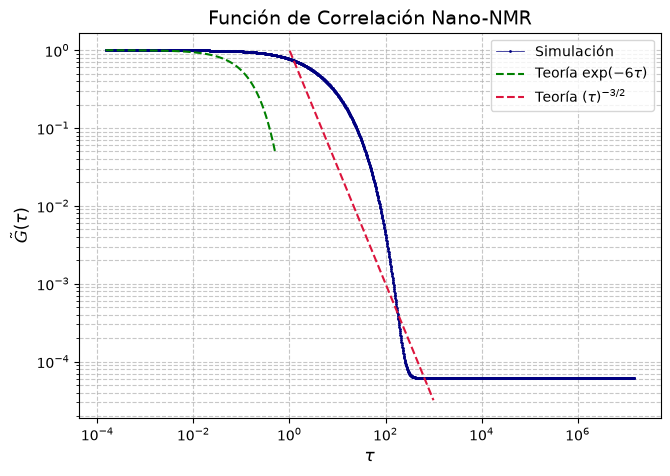

In [25]:
np.savetxt("data/G_vs_t_tworegion_z'.dat", np.c_[t_values, G_values], header="Tiempo(s) G(t)", fmt="%.9e")

plt.figure(figsize=(7.5,5))
plt.loglog(tau_values, G_values/G_values[0], "o-", label="Simulación", color="navy", markersize=1, linewidth=0.5)
plt.plot(tau_values[tau_values<0.5], np.exp(-6*tau_values[tau_values<0.5]), "--", label=r"Teoría $\exp(-6\tau)$", color="green", linewidth=1.5)
plt.plot(tau_values[(tau_values>=1)&(tau_values<=1000)], (tau_values[(tau_values>=1)&(tau_values<=1000)])**-1.5, "--", label=r"Teoría $(\tau)^{-3/2}$", color="crimson", linewidth=1.5)
# plt.xlabel("Tiempo (s)", fontsize=12)
plt.xlabel(r"$\tau$", fontsize=12)
plt.ylabel(r"$\tilde{G}(\tau)$", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.grid(which="both", ls='--', alpha=0.7)
plt.savefig("figuras/correlacion_nanoNMR_tworegion_z'.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()

## Análisis de truncamiento modal

In [26]:
modes_list = np.arange(5,105,5)

In [27]:
G_dict     = {}
weights_dict = {}

for modes in modes_list:
    print(f"--- Truncando a {modes} modos ---")
    # 1) Subconjuntos de datos
    R0_mat_sub = R0_mat[:modes, :]               # (modes, Nr)
    evals_sub  = eigenvalues_ax[:modes, :modes]  # (modes, modes)
    Z_tens_sub = Z_tens[:, :modes, :modes]       # (Nquad, modes, modes)

    # 2) F_nm para este subconjunto — integral doble correcta
    R_rho_sub = R0_mat_sub * (rho_nodes * w_rho)[None, :]  # (modes, Nr)
    B_nj_sub  = np.dot(R_rho_sub, f_mat)         # (modes, Nz)
    F_nm_sub  = np.zeros((modes, modes))
    for _n in range(modes):
        F_nm_sub[_n, :] = (B_nj_sub[_n, :] * w_z) @ Z_tens_sub[:, _n, :]

    # 3) G(t) = (5/16pi) sum F_nm_sub^2 exp(-Lambda t)
    G_vals = np.zeros_like(t_values)
    for i, t in enumerate(t_values):
        T_decay = np.exp(-np.abs(evals_sub) * t)
        G_vals[i] = (5/(16*np.pi)) * np.sum(F_nm_sub**2 * T_decay)
    G_dict[modes] = G_vals

    # 4) Pesos modales normalizados F_nm^2 / sum F_nm^2
    w = F_nm_sub.flatten()**2
    weights_dict[modes] = w / np.sum(w)

--- Truncando a 5 modos ---
--- Truncando a 10 modos ---
--- Truncando a 15 modos ---
--- Truncando a 20 modos ---
--- Truncando a 25 modos ---
--- Truncando a 30 modos ---
--- Truncando a 35 modos ---
--- Truncando a 40 modos ---
--- Truncando a 45 modos ---
--- Truncando a 50 modos ---
--- Truncando a 55 modos ---
--- Truncando a 60 modos ---
--- Truncando a 65 modos ---
--- Truncando a 70 modos ---
--- Truncando a 75 modos ---
--- Truncando a 80 modos ---
--- Truncando a 85 modos ---
--- Truncando a 90 modos ---
--- Truncando a 95 modos ---
--- Truncando a 100 modos ---


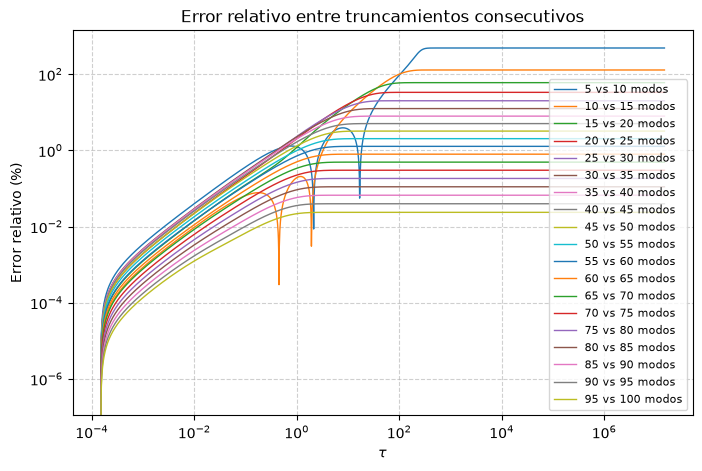

In [28]:
plt.figure(figsize=(8,5))
for i in range(len(modes_list)-1):
    m0, m1 = modes_list[i], modes_list[i+1]
    err = np.abs(G_dict[m0]/G_dict[m0][0] - G_dict[m1]/G_dict[m1][0]) / (G_dict[m1]/G_dict[m1][0]) * 100
    plt.loglog(tau_values, err, label=f"{m0} vs {m1} modos", linewidth=1)

plt.xlabel(r"$\tau$")
# plt.ylim((1,100))
plt.ylabel("Error relativo (%)")
plt.title("Error relativo entre truncamientos consecutivos")
plt.legend(fontsize=8)
plt.grid(which="both", ls='--', alpha=0.6)
plt.savefig("figuras/error_vs_t_tworegion_z'.pdf", bbox_inches="tight", dpi=300)
plt.show()

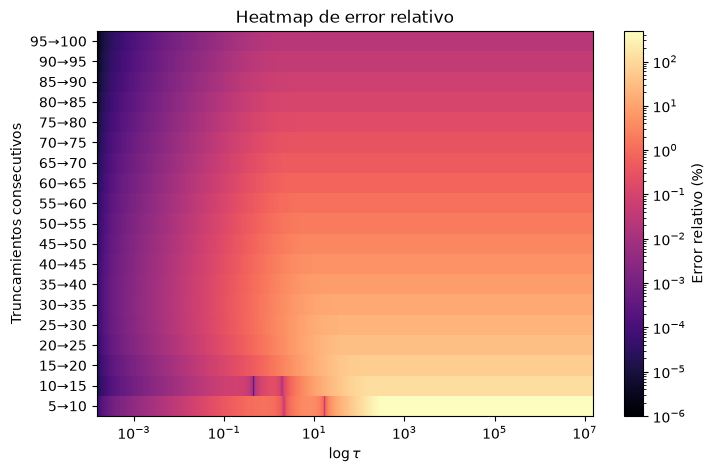

In [29]:
# 3.1. Construye la matriz de errores E (shape N_pairs × N_t)
E = []
labels = []
for i in range(len(modes_list)-1):
    m0, m1 = modes_list[i], modes_list[i+1]
    err = np.abs(G_dict[m0]/G_dict[m0][0] - G_dict[m1]/G_dict[m1][0]) / (G_dict[m1]/G_dict[m1][0]) * 100
    E.append(err)
    labels.append(f"{m0}→{m1}")
E = np.array(E)

# 3.2. Prepara los “bin edges” de tiempo en log
#    pcolormesh necesita los bordes de las celdas:
tau_edges = np.logspace(np.log10(tau_values[0]), np.log10(tau_values[-1]), len(tau_values)+1)
y_edges = np.arange(len(labels)+1)

# 3.3. Dibuja
plt.figure(figsize=(8,5))
mesh = plt.pcolormesh(tau_edges, y_edges, E, norm=LogNorm(vmin=E.min()+1e-6, vmax=E.max()),
                      cmap="magma")
plt.xscale("log")
plt.yticks(np.arange(0.5, len(labels)+0.5), labels)
plt.xlabel(r"$\log\tau$")
plt.ylabel("Truncamientos consecutivos")
plt.title("Heatmap de error relativo")
plt.colorbar(mesh, label="Error relativo (%)")
plt.savefig("figuras/heatmap_error_tworegion_z'.pdf", bbox_inches="tight", dpi=300)
plt.show()

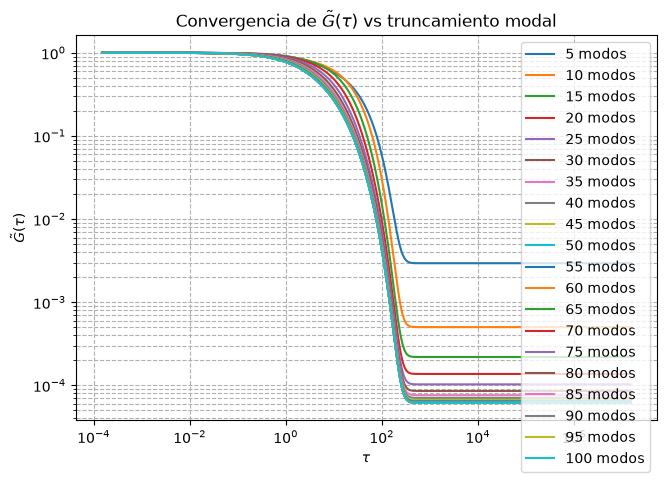

In [30]:
plt.figure(figsize=(7.5,5))
for modes in modes_list:
    Gv = G_dict[modes]
    plt.loglog(tau_values,
               Gv / Gv[0],
               label=f"{modes} modos")
plt.xlabel(r"$\tau$")
plt.ylabel(r"$\tilde{G}(\tau)$")
plt.title(r"Convergencia de $\tilde{G}(\tau)$ vs truncamiento modal")
plt.legend()
plt.grid(which="both", ls="--")
plt.savefig("figuras/convergencia_correlacion_tworegion_z'.pdf", bbox_inches="tight", dpi=300)
plt.show()

## Conclusiones

El modelo de dos regiones en coordenada desplazada $z'$ reproduce fielmente el comportamiento de la función de correlación Nano-NMR:

- La suma modal converge rápidamente: con 50–100 modos el error relativo entre truncamientos consecutivos es inferior al 1% en todo el rango de $\tau$.
- El heatmap de error y las curvas de convergencia muestran que la región de mayor sensibilidad al número de modos se sitúa en $\tau \sim 1\text{–}10$, correspondiente a la escala temporal de difusión a través de la capa superficial.
- Los perfiles $P(\rho, z', t)$ calculados con `compute_P_vec` muestran la dispersión progresiva de la distribución de probabilidad desde la condición inicial $(0, 0)$ hacia el volumen del cilindro.
- La eficiencia computacional es notable: los autovalores axiales $\Lambda_{nm}$ se hallan por búsqueda de raíces de la ecuación trascendental sin diagonalizar matrices dispersas grandes, permitiendo tratar 100×100 modos en segundos.